# Frozen Hallmark-state retrieval from TCGA into ARCHS4

## Scientific question

Can the frozen Bridge sample representation support two distinct search modes over ARCHS4: global similarity in the original 512-dimensional representation and interpretable functional-state similarity after projection into 50 Hallmark programs?

The hypothesis is that the frozen Hallmark projection will preserve pathway-profile similarity while retrieving a neighborhood that only partly overlaps the global Bridge neighborhood. The comparison is not designed to establish that either search mode is universally superior.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
PACKAGE = Path.cwd()
if not (PACKAGE / "data").exists():
    PACKAGE = Path("notebooks/tcga_archs4_state_retrieval").resolve()
DATA = PACKAGE / "data"
FIGURES = PACKAGE / "figures"
FIGURES.mkdir(exist_ok=True)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.show()

individual = pd.read_csv(DATA / "individual_method_overlap.csv")
centroid = pd.read_csv(DATA / "centroid_method_overlap.csv")
preservation = pd.read_csv(DATA / "functional_profile_preservation.csv")
expression = pd.read_csv(DATA / "expression_subset_method_overlap.csv")
metadata = pd.read_csv(DATA / "metadata_coherence.csv")
dominant = pd.read_csv(DATA / "dominant_pathway_removal_summary.csv")
pathways = pd.read_csv(DATA / "pathway_wise_preservation.csv")
query_profiles = pd.read_csv(DATA / "tcga_centroid_hallmark_profiles.csv", index_col=0)
retrieved_profiles = pd.read_csv(DATA / "retrieved_archs4_mean_hallmark_profiles.csv", index_col=0)
qa = json.loads((DATA / "qa.json").read_text())
headline = json.loads((DATA / "headline_summary.json").read_text())
independent_cancers = pd.read_csv(DATA / "independent_cancer_profile_concordance.csv")
independent_pathways = pd.read_csv(DATA / "independent_pathway_ranking_concordance.csv")
independent_summary = json.loads((DATA / "independent_validation_summary.json").read_text())
extended_retrieval = pd.read_csv(DATA / "extended_retrieval_metrics.csv")
signal_matching = pd.read_csv(DATA / "signal_matching_summary.csv")
osdr_summary = json.loads((DATA / "osdr_scientific_summary.json").read_text())
multispecies = pd.read_csv(DATA / "multispecies_topk_comparison.csv")
multispecies_provenance = json.loads((DATA / "multispecies_provenance.json").read_text())

assert qa["passed"] is True
assert qa["dimensions"] == {
    "archs4_bridge": [510709, 512], "tcga_bridge": [9816, 512],
    "archs4_hallmark": [510709, 50], "tcga_hallmark": [9816, 50]
}
assert len(individual) == 9816 * 6 and individual.query_index.nunique() == 9816
assert len(centroid) == 32 * 6 and centroid.cancer_type.nunique() == 32
assert query_profiles.shape == retrieved_profiles.shape == (32, 50)
assert np.isfinite(query_profiles.to_numpy()).all()
assert np.isfinite(retrieved_profiles.to_numpy()).all()
assert independent_cancers.shape == (32, 4)
assert independent_pathways.shape == (50, 2)
assert multispecies_provenance["combined_reference_samples"] == 940455
print("Cached evidence loaded; cohort, dimensions, ordering, and finite-value checks passed.")

Cached evidence loaded; cohort, dimensions, ordering, and finite-value checks passed.


## Data and frozen Hallmark readout

The query cohort contains **9,816 TCGA primary tumors**, one specimen per patient, spanning **32 cancer types**. The reference database contains **510,709 unique human ARCHS4 samples**. Bridge inputs use natural `log1p(TPM)` in the exact canonical 15,165-gene order. Bridge remains frozen, and its sample embedding is the unweighted mean of final-layer contextual gene states.

The Hallmark head was trained previously using **4,260 GTEx samples from 920 donors and 12 broad tissues**:

1. Rank all 15,165 genes within each GTEx sample and divide each rank by 15,165.
2. For each of 50 MSigDB Hallmarks, average the normalized ranks of its canonical member genes.
3. Standardize each expression-derived Hallmark target across GTEx.
4. Standardize the 512 Bridge coordinates using GTEx training means and standard deviations.
5. Fit a 50-output Ridge model with one global penalty selected from `0.01, 0.1, 1, 10, 100` by five-fold donor-grouped cross-validation. The selected penalty was `alpha=0.1`; the final scaler and model were refit on all GTEx samples and frozen.

For an unseen sample with Bridge embedding $z$, inference is

$$
P(z) = \left(\frac{z-\mu_{GTEx}}{\sigma_{GTEx}}\right)W^T + b.
$$

The outputs are continuous **Bridge Hallmark scores** predicting GTEx-standardized rank-mean targets. They are not probabilities, GSEA enrichment scores, formal ssGSEA scores, causal pathway activities, or gene-level decoder outputs. Neither TCGA nor ARCHS4 labels were used to fit this mapping.

## Independent validation of the Hallmark coordinate system

Before interpreting retrieval, the frozen readout was tested against Hallmark profiles computed independently from TCGA expression. Across 32 cancer types, the mean Pearson correlation between conventional and Bridge-predicted 50-Hallmark cancer profiles was **0.756**. Cancer-to-cancer geometry agreed much more strongly with conventional Hallmark geometry after the frozen Hallmark projection than in the original Bridge space: similarity-matrix Spearman was **0.862** for Hallmark-50 and **0.388** for Bridge-512. Across the 50 pathways, the median Spearman correlation of cancer rankings was **0.824**.

This is independent evidence that the head recovers recognizable Hallmark structure beyond GTEx. The conventional comparator is a deterministic rank-mean, ssGSEA-like profile on the same 15,165-gene vocabulary; it is not exact ssGSEA 2.0 NES and should not be described as such.

,validation quantity,value
0,Mean cancer-profile Pearson,0.756
1,Cancer geometry Spearman: Hallmark-50,0.862
2,Cancer geometry Spearman: Bridge-512,0.388
3,Median pathway cancer-ranking Spearman,0.824


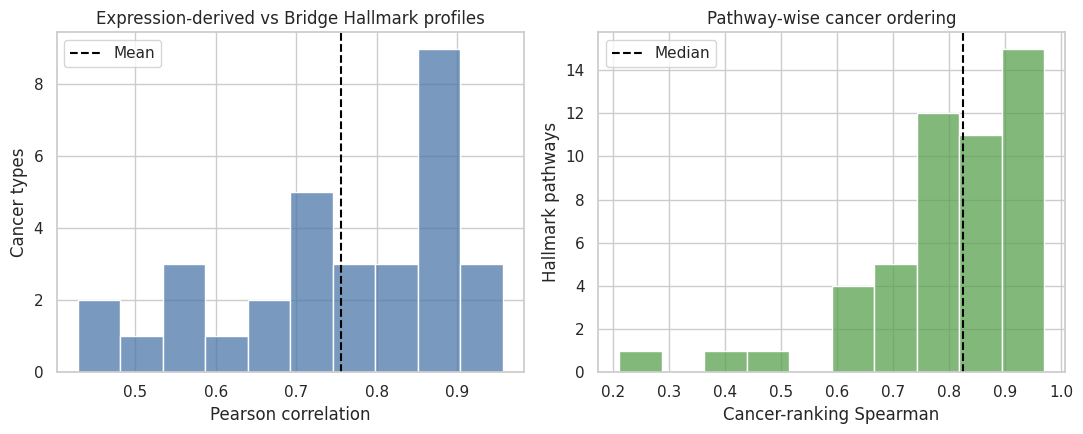

In [2]:
iv = independent_summary["metrics"]
validation_table = pd.DataFrame({
    "validation quantity": [
        "Mean cancer-profile Pearson",
        "Cancer geometry Spearman: Hallmark-50",
        "Cancer geometry Spearman: Bridge-512",
        "Median pathway cancer-ranking Spearman",
    ],
    "value": [
        iv["mean_cancer_profile_pearson"],
        iv["similarity_matrix_spearman_conventional_vs_bridge_hallmark"],
        iv["similarity_matrix_spearman_conventional_vs_bridge512"],
        iv["median_pathway_ranking_spearman"],
    ],
})
display(validation_table.round({"value": 3}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(independent_cancers["pearson_conventional_vs_bridge_hallmark"], bins=10,
             color="#4C78A8", ax=axes[0])
axes[0].axvline(independent_cancers["pearson_conventional_vs_bridge_hallmark"].mean(),
                color="black", linestyle="--", label="Mean")
axes[0].set(xlabel="Pearson correlation", ylabel="Cancer types",
            title="Expression-derived vs Bridge Hallmark profiles")
axes[0].legend()
sns.histplot(independent_pathways["cancer_ranking_spearman"], bins=10,
             color="#59A14F", ax=axes[1])
axes[1].axvline(independent_pathways["cancer_ranking_spearman"].median(),
                color="black", linestyle="--", label="Median")
axes[1].set(xlabel="Cancer-ranking Spearman", ylabel="Hallmark pathways",
            title="Pathway-wise cancer ordering")
axes[1].legend()
savefig(fig, "independent_tcga_validation")

## Retrieval protocol

Every TCGA patient independently queried the complete ARCHS4 reference collection, and each of the 32 cancer types also supplied a centroid query. The same query definitions were used for:

- **Bridge-512:** cosine similarity in the frozen sample representation.
- **Hallmark-50:** cosine similarity between the frozen 50-dimensional Bridge Hallmark profiles.

Top 1, 5, 10, 25, 50, and 100 neighbors were retained. The methods were compared by overlap count, Jaccard similarity, shared-candidate rank correlation, metadata keyword coherence, study diversity, pathway-profile preservation, dominant-pathway removal, and universal-neighbor frequency.

A conventional expression baseline used the same 32 cancer centroids and a deterministic 40,000-sample ARCHS4 subset represented by the exact 15,165-gene natural `log1p(TPM)` matrix. Bridge, Hallmark, and expression retrieval were recomputed on this identical candidate universe. The expression comparison is therefore centroid-only and subset-scoped.

In [3]:
i100 = individual[individual.k.eq(100)]
c100 = centroid[centroid.k.eq(100)]
summary = pd.DataFrame({
    "query mode": ["Individual TCGA samples", "Cancer centroids"],
    "queries": [i100.query_index.nunique(), c100.query_index.nunique()],
    "median overlap@100": [i100.overlap_count.median(), c100.overlap_count.median()],
    "median Jaccard@100": [i100.jaccard.median(), c100.jaccard.median()],
    "Jaccard IQR low": [i100.jaccard.quantile(.25), c100.jaccard.quantile(.25)],
    "Jaccard IQR high": [i100.jaccard.quantile(.75), c100.jaccard.quantile(.75)],
})
assert np.isclose(summary.loc[0, "median Jaccard@100"], headline["individual_bridge_hallmark_jaccard100_median"])
assert np.isclose(summary.loc[1, "median Jaccard@100"], headline["centroid_bridge_hallmark_jaccard100_median"])
display(summary.round({
    "median overlap@100": 0, "median Jaccard@100": 3,
    "Jaccard IQR low": 3, "Jaccard IQR high": 3
}))

,query mode,queries,median overlap@100,median Jaccard@100,Jaccard IQR low,Jaccard IQR high
0,Individual TCGA samples,9816,20.0,0.111,0.064,0.176
1,Cancer centroids,32,22.0,0.124,0.093,0.220


## Hallmark retrieval identifies a distinct neighborhood

The two frozen representations produced markedly different nearest-neighbor sets. Individual-query Bridge/Hallmark overlap was **20 of 100 samples at the median**, corresponding to median Jaccard **0.111** (IQR **0.064–0.176**). Cancer-centroid overlap was **22 of 100**, with median Jaccard **0.124** (IQR **0.093–0.220**). Hallmark-50 therefore acts as a distinct supervised pathway-state view rather than a lossless compression of Bridge-512 retrieval.

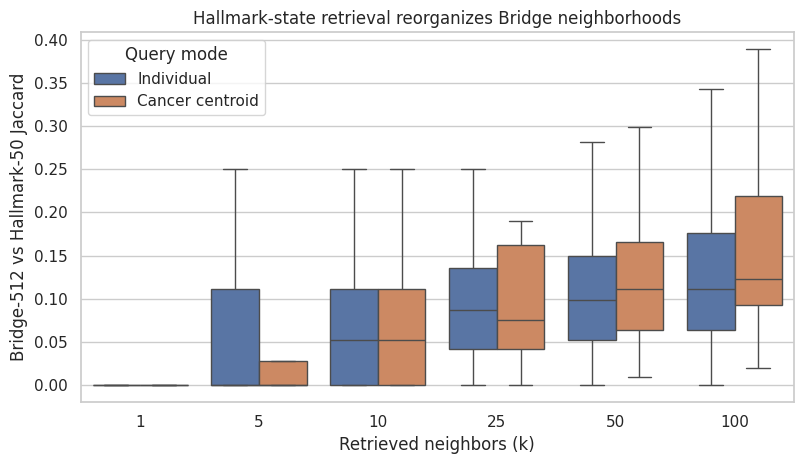

In [4]:
plot_overlap = pd.concat([
    individual.assign(query_mode="Individual"),
    centroid.assign(query_mode="Cancer centroid")
], ignore_index=True)
fig, ax = plt.subplots(figsize=(8.2, 4.8))
sns.boxplot(data=plot_overlap, x="k", y="jaccard", hue="query_mode", showfliers=False, ax=ax)
ax.set(xlabel="Retrieved neighbors (k)", ylabel="Bridge-512 vs Hallmark-50 Jaccard",
       title="Hallmark-state retrieval reorganizes Bridge neighborhoods")
ax.legend(title="Query mode")
savefig(fig, "bridge_hallmark_overlap")

## Functional-profile preservation

Across 32 cancer centroids, the Spearman correlation between each TCGA Hallmark vector and the mean Hallmark vector of its top 100 Hallmark-retrieved ARCHS4 samples was **0.960 at the median** (IQR **0.935–0.975**; range **0.810–0.990**). This verifies that retrieval preserves the coordinates on which it is performed, but it is selection-conditioned and is not independent evidence of shared mechanism.

Pathway-wise preservation was heterogeneous. Apoptosis (`0.978`), Mitotic Spindle (`0.974`), and Hypoxia (`0.972`) were among the strongest across cancers, whereas Myogenesis (`0.814`) and Spermatogenesis (`0.777`) were weaker.

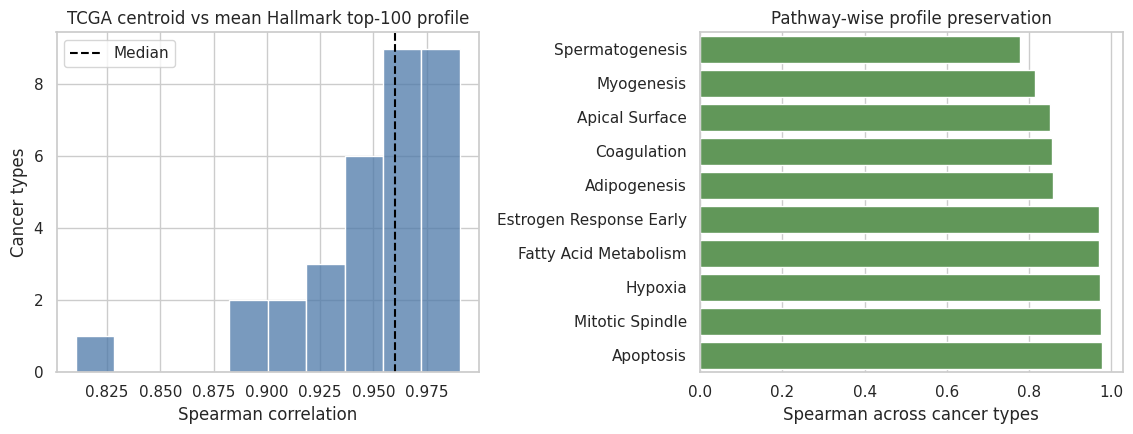

In [5]:
assert np.isclose(preservation.spearman.median(), headline["functional_profile_preservation_spearman_median"])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
sns.histplot(preservation.spearman, bins=10, color="#4C78A8", ax=axes[0])
axes[0].axvline(preservation.spearman.median(), color="black", linestyle="--", label="Median")
axes[0].set(xlabel="Spearman correlation", ylabel="Cancer types",
            title="TCGA centroid vs mean Hallmark top-100 profile")
axes[0].legend()
ordered = pathways.sort_values("spearman_across_cancers")
show = pd.concat([ordered.head(5), ordered.tail(5)]).drop_duplicates()
sns.barplot(data=show, y="hallmark", x="spearman_across_cancers", color="#59A14F", ax=axes[1])
axes[1].set(xlabel="Spearman across cancer types", ylabel="",
            title="Pathway-wise profile preservation")
savefig(fig, "functional_profile_preservation")

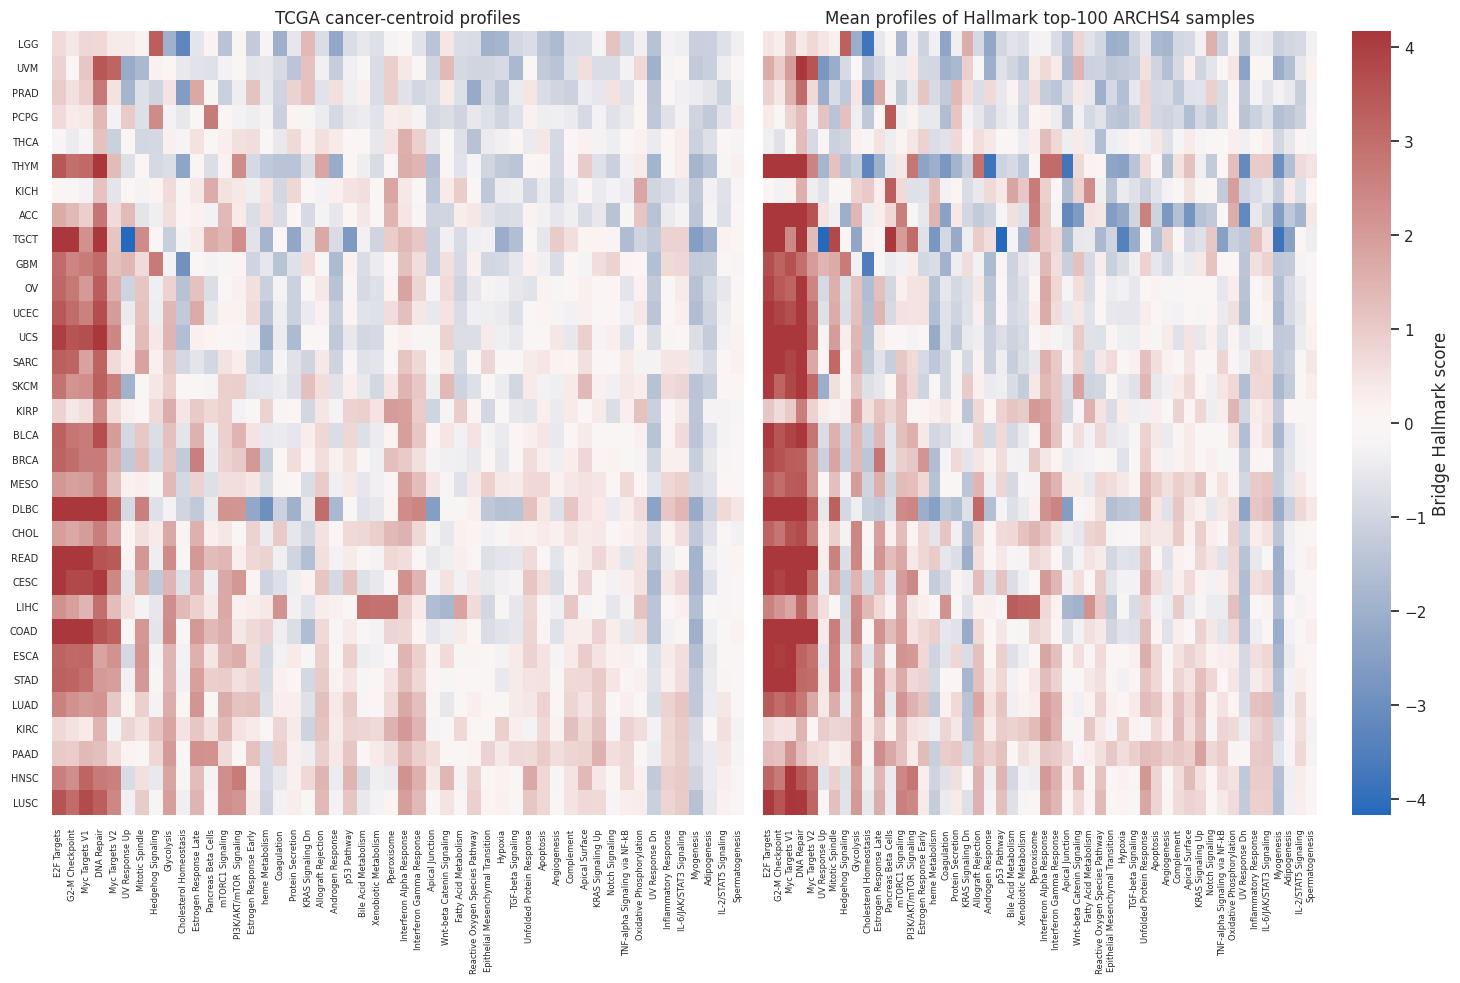

In [6]:
row_order = query_profiles.mean(axis=1).sort_values().index
col_order = query_profiles.var(axis=0).sort_values(ascending=False).index
v = np.nanpercentile(np.abs(np.r_[query_profiles.to_numpy().ravel(), retrieved_profiles.to_numpy().ravel()]), 98)
fig, axes = plt.subplots(1, 2, figsize=(15, 10), sharey=False)
sns.heatmap(query_profiles.loc[row_order, col_order], cmap="vlag", center=0, vmin=-v, vmax=v,
            cbar=False, xticklabels=True, yticklabels=True, ax=axes[0])
sns.heatmap(retrieved_profiles.loc[row_order, col_order], cmap="vlag", center=0, vmin=-v, vmax=v,
            cbar_kws={"label": "Bridge Hallmark score"}, xticklabels=True, yticklabels=False, ax=axes[1])
axes[0].set_title("TCGA cancer-centroid profiles")
axes[1].set_title("Mean profiles of Hallmark top-100 ARCHS4 samples")
for ax in axes:
    ax.tick_params(axis="x", labelsize=6, rotation=90)
    ax.tick_params(axis="y", labelsize=7)
savefig(fig, "centroid_hallmark_profiles")

## Expression baseline and metadata tradeoff

On the common 40,000-sample expression candidate set, median Jaccard@100 was **0.205** for Bridge/expression, **0.156** for Hallmark/expression, and **0.133** for Bridge/Hallmark across the 32 cancer centroids. Expression retrieval was related to both frozen representations but identical to neither.

At individual-query top 100, median organ-keyword agreement was **0.460** for Bridge and **0.400** for Hallmark. Median unique-study counts were **31** and **34**, respectively, and the median maximum single-study fraction was **0.17** for both. Thus Hallmark retrieval does not improve coarse tissue lookup; its value is the alternative functional-program view. ARCHS4 keyword annotations are incomplete free-text proxies rather than biological ground truth.

,comparison,jaccard
0,bridge_vs_expression,0.205
1,bridge_vs_hallmark,0.133
2,hallmark_vs_expression,0.156


,method,organ_keyword_agreement,unique_studies,max_study_fraction
0,bridge512_cosine,0.46,31.0,0.17
1,hallmark50_cosine,0.40,34.0,0.17


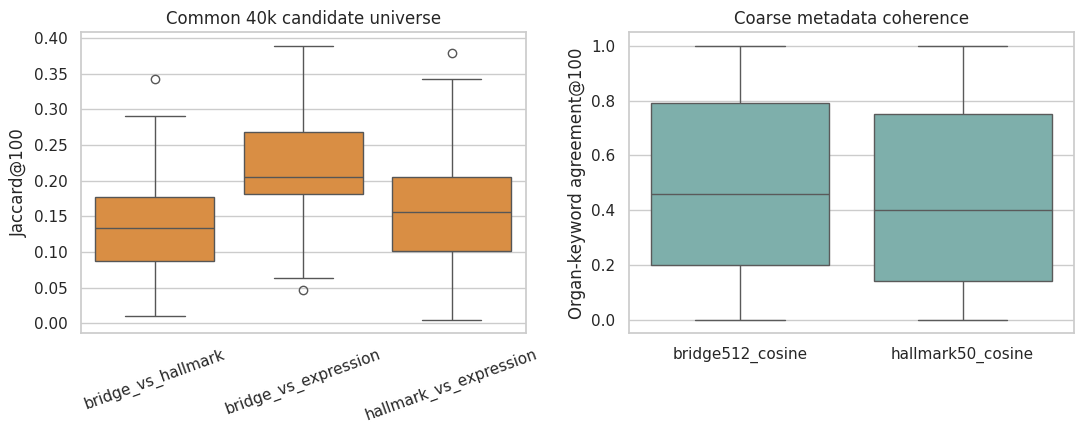

In [7]:
e100 = expression[expression.k.eq(100)]
m100 = metadata[(metadata.query_mode.eq("individual")) & metadata.k.eq(100)]
expr_summary = e100.groupby("comparison", as_index=False).jaccard.median()
meta_summary = m100.groupby("method", as_index=False).agg(
    organ_keyword_agreement=("organ_keyword_agreement", "median"),
    unique_studies=("unique_studies", "median"),
    max_study_fraction=("max_study_fraction", "median")
)
display(expr_summary.round({"jaccard": 3}))
display(meta_summary.round({
    "organ_keyword_agreement": 3, "unique_studies": 0, "max_study_fraction": 2
}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=e100, x="comparison", y="jaccard", color="#F28E2B", ax=axes[0])
axes[0].tick_params(axis="x", rotation=20)
axes[0].set(xlabel="", ylabel="Jaccard@100", title="Common 40k candidate universe")
sns.boxplot(data=m100, x="method", y="organ_keyword_agreement", color="#76B7B2", showfliers=False, ax=axes[1])
axes[1].set(xlabel="", ylabel="Organ-keyword agreement@100", title="Coarse metadata coherence")
savefig(fig, "expression_and_metadata_comparison")

## Extended 33-cancer retrieval audit

The broader audit separates two questions that should not be conflated. For **patient-level disease lookup at top 50**, Bridge-512 was stronger: exact-disease precision was **0.338** versus **0.305**, tissue precision **0.424** versus **0.395**, and malignancy precision **0.777** versus **0.707** for Hallmark cosine. For **cancer-centroid retrieval at top 10**, performance was much closer: exact-disease precision was **0.488** for Bridge and **0.482** for Hallmark, while tissue precision was **0.506** and **0.512**.

Hallmark cosine covered more of the query's signed pathway signal at top 10 (**0.791** versus **0.707** for Bridge). A signed top-10 Hallmark-overlap mode raised signal coverage to **0.888**, but exact-disease precision fell to **0.388**. This is a useful tradeoff, not evidence that one metric dominates. UVM and CHOL were favorable centroid examples for Hallmark retrieval (8/10 versus 6/10 and 9/10 versus 6/10 exact matches), while LUAD retrieved biologically related LUSC samples; these remain descriptive metadata-compatible cases.

method,Bridge-512 cosine,Hallmark-50 cosine
criterion,,
Exact disease,0.338,0.304
Malignancy,0.777,0.707
Tissue,0.424,0.395


,method,exact_disease_precision,tissue_precision,malignancy_precision,signal_coverage_top10
1,Bridge-512 reference,0.488,0.506,0.864,0.707
13,signed_top10_overlap,0.388,0.452,0.776,0.888
19,whole_vector_cosine,0.482,0.512,0.855,0.791


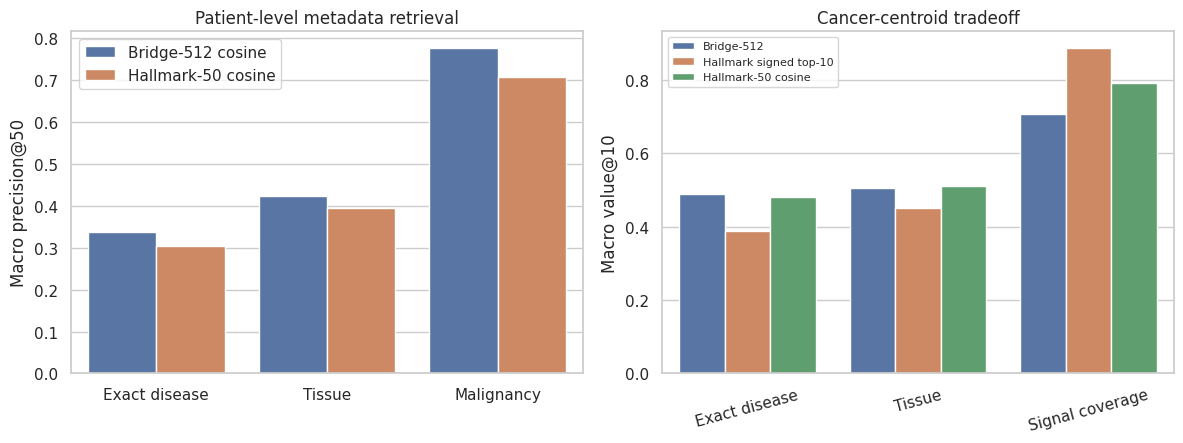

In [8]:
def metric_value(method, criterion, k=50):
    row = extended_retrieval[
        extended_retrieval.method.eq(method) &
        extended_retrieval.criterion.eq(criterion) &
        extended_retrieval.k.eq(k)
    ]
    assert len(row) == 1
    return row.macro_precision.iloc[0]

patient_rows = []
for criterion, label in [("exact_disease", "Exact disease"),
                         ("tissue_organ", "Tissue"),
                         ("malignancy", "Malignancy")]:
    for method in ["Bridge-512 cosine", "Hallmark-50 cosine"]:
        patient_rows.append({"criterion": label, "method": method,
                             "precision": metric_value(method, criterion)})
patient_summary = pd.DataFrame(patient_rows)

s10 = signal_matching[signal_matching.k.eq(10)].copy()
keep_methods = ["Bridge-512 reference", "whole_vector_cosine", "signed_top10_overlap"]
s10 = s10[s10.method.isin(keep_methods)]
display(patient_summary.pivot(index="criterion", columns="method", values="precision").round(3))
display(s10[["method", "exact_disease_precision", "tissue_precision",
             "malignancy_precision", "signal_coverage_top10"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(data=patient_summary, x="criterion", y="precision", hue="method", ax=axes[0])
axes[0].set(xlabel="", ylabel="Macro precision@50", title="Patient-level metadata retrieval")
axes[0].legend(title="")
centroid_plot = s10.melt(id_vars="method",
    value_vars=["exact_disease_precision", "tissue_precision", "signal_coverage_top10"],
    var_name="criterion", value_name="value")
centroid_plot["criterion"] = centroid_plot["criterion"].map({
    "exact_disease_precision": "Exact disease",
    "tissue_precision": "Tissue",
    "signal_coverage_top10": "Signal coverage",
})
centroid_plot["method"] = centroid_plot["method"].map({
    "Bridge-512 reference": "Bridge-512",
    "whole_vector_cosine": "Hallmark-50 cosine",
    "signed_top10_overlap": "Hallmark signed top-10",
})
sns.barplot(data=centroid_plot, x="criterion", y="value", hue="method", ax=axes[1])
axes[1].set(xlabel="", ylabel="Macro value@10", title="Cancer-centroid tradeoff")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="", fontsize=8)
savefig(fig, "extended_retrieval_tradeoff")

## Cross-study replication and the cross-species boundary

The same frozen system was applied to 1,471 OSDR mouse samples in 88 eligible experimental groups. Hallmark cosine had higher top-10 replicate-neighbor consistency than Bridge-512 (**0.613–0.629** versus **0.366–0.386** across flight and ground-control conditions), but also showed stronger hub effects and weaker tissue contextualization. Among 435 strict flight-enriched retrievals from 24 groups, Bridge supplied 233, Hallmark cosine 179, and signed Hallmark overlap 23.

Expanding the database to **940,455** human and mouse ARCHS4 samples revealed a strong domain boundary. At top 10, the mouse fraction was **99.53%** for Bridge and **100%** for both Hallmark modes. Hallmark tissue coherence improved from **0.063** when mouse queries were forced into the human-only atlas to **0.635** in the combined atlas. The pathway system is portable as a coordinate system, but cross-species nearest-neighbor retrieval is not species-invariant.

,method,condition,neighbor_jaccard
0,Bridge-512 cosine,Flight,0.366
1,Bridge-512 cosine,Ground control,0.386
2,Hallmark signed top10 overlap,Flight,0.516
3,Hallmark signed top10 overlap,Ground control,0.494
4,Hallmark-50 cosine,Flight,0.613
5,Hallmark-50 cosine,Ground control,0.629


,reference_set,method,mouse_fraction,tissue_coherence
9,combined,Bridge-512 cosine,0.995,0.598
10,combined,Hallmark signed top10 overlap,1.000,0.605
11,combined,Hallmark-50 cosine,1.000,0.635
12,human,Bridge-512 cosine,0.000,0.560
13,human,Hallmark signed top10 overlap,0.000,0.188
14,human,Hallmark-50 cosine,0.000,0.063
15,mouse,Bridge-512 cosine,1.000,0.597
16,mouse,Hallmark signed top10 overlap,1.000,0.628
17,mouse,Hallmark-50 cosine,1.000,0.634


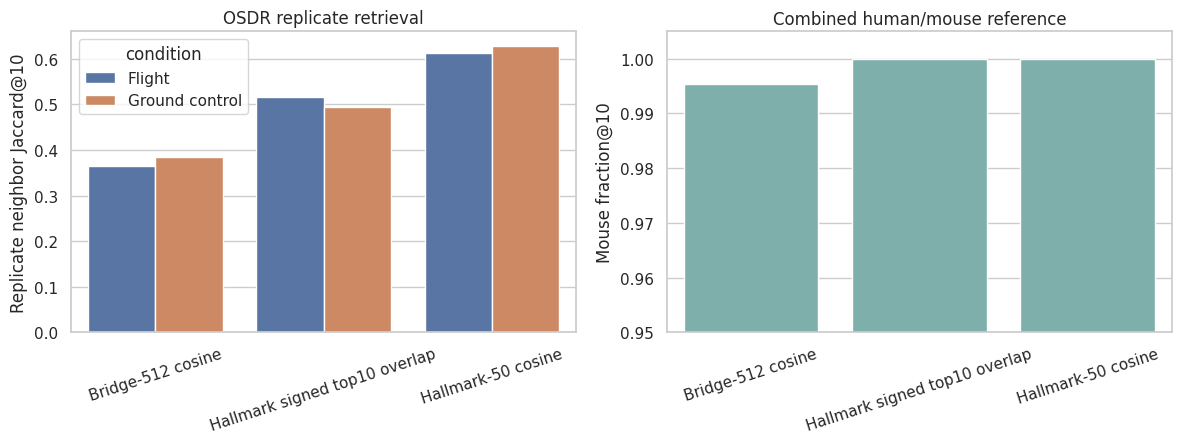

In [9]:
rep = pd.DataFrame(osdr_summary["macro_replicate_consistency_top10"])
rep["condition"] = rep.condition.map({"FLT": "Flight", "GC": "Ground control"})
m10 = multispecies[multispecies.k.eq(10)].copy()
display(rep[["method", "condition", "neighbor_jaccard"]].round(3))
display(m10[["reference_set", "method", "mouse_fraction", "tissue_coherence"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(data=rep, x="method", y="neighbor_jaccard", hue="condition", ax=axes[0])
axes[0].set(xlabel="", ylabel="Replicate neighbor Jaccard@10",
            title="OSDR replicate retrieval")
axes[0].tick_params(axis="x", rotation=18)
combined = m10[m10.reference_set.eq("combined")]
sns.barplot(data=combined, x="method", y="mouse_fraction", color="#76B7B2", ax=axes[1])
axes[1].set(xlabel="", ylabel="Mouse fraction@10", ylim=(0.95, 1.005),
            title="Combined human/mouse reference")
axes[1].tick_params(axis="x", rotation=18)
savefig(fig, "cross_study_and_species_boundary")

## Controls and limitations

- Removing the strongest one or three Hallmark coordinates retained median Jaccard@100 of **0.896** and **0.794**, respectively, although minima of **0.282** and **0.299** show that robustness was not universal.
- The most frequent Bridge and Hallmark database samples appeared in **714** and **663** individual top-100 lists, compared with an approximately **1.92** uniform expectation. Study identity and hub frequency should accompany interpretation of individual matches.
- The ARCHS4 database contains Bridge training, validation, and unseen samples; this is a full-corpus search evaluation rather than a strict unseen-sample test.
- Exact identifier checks found no TCGA/ARCHS4 overlap, but do not rule out biologically duplicated material deposited under unrelated identifiers.
- The expression baseline is restricted to cancer centroids and 40,000 cached candidates.
- Similarity and metadata coherence do not demonstrate shared mechanism, causal pathway activation, or clinical equivalence.

In [10]:
control_summary = dominant.groupby("dimensions_removed", as_index=False).agg(
    median_jaccard=("jaccard", "median"),
    minimum_jaccard=("jaccard", "min"),
    maximum_jaccard=("jaccard", "max")
)
display(control_summary.round({
    "median_jaccard": 3, "minimum_jaccard": 3, "maximum_jaccard": 3
}))
assert np.isclose(control_summary.loc[control_summary.dimensions_removed.eq(1), "median_jaccard"].iloc[0], 0.8957771787960467)
assert np.isclose(control_summary.loc[control_summary.dimensions_removed.eq(3), "median_jaccard"].iloc[0], 0.7937580437580438)
print("All packaged headline metrics reproduce the cached benchmark summaries.")

,dimensions_removed,median_jaccard,minimum_jaccard,maximum_jaccard
0,1,0.896,0.282,1.000
1,3,0.794,0.299,0.923


All packaged headline metrics reproduce the cached benchmark summaries.


## Conclusion

The frozen GTEx-trained Hallmark head converts Bridge sample embeddings into a common 50-dimensional functional-program coordinate system without adapting to TCGA or ARCHS4. Its TCGA cancer profiles independently agree with expression-derived Hallmark structure, and Hallmark-50 retrieval preserves that profile while returning substantially different ARCHS4 neighborhoods from Bridge-512 and conventional expression retrieval.

The positive result is therefore not that Hallmark retrieval is universally more accurate. Bridge remained better for several patient-level disease and tissue criteria. Hallmark retrieval adds a complementary, pathway-decomposable search mode, broader functional-signal coverage, and useful centroid-level examples. Cross-species analyses show that the same frozen coordinates can be computed in mouse, but retrieval remains strongly species/domain structured and requires species-matched references.

### References

- Liberzon A. *et al.* The Molecular Signatures Database Hallmark Gene Set Collection. *Cell Systems* (2015).
- Frozen model, cohort, and artifact hashes are recorded in `data/package_provenance.json`.